# 11-AI策略生成关节运控指令


## 1. 本课目标：给机器人接上策略网络

本篇对应《具身智能机器人实战》第 11 节《AI 策略生成关节运控指令》，副标题为“mnn 策略网络给机器人接上大脑”。上一节发现，手动逐个调整 20 多个关节既低效又难以协调。本节转向 AI 策略：根据当前状态生成动作，让多个关节共同完成运动。

**资料依据：**[课程百度网盘资料](https://pan.baidu.com/s/1TI1Opoqy_jjmWCzhUOwliw?pwd=1234)，提取码 `1234`。已逐页核对 `ppt/11_AI策略生成关节运控指令.pptx` 全部 4 页：第 2 页用走路说明协调问题，第 3 页用游戏角色说明状态、动作选择与训练反馈，第 4 页为品牌结束页。

课件没有展示 MNN 模型加载代码、输入输出维度、训练算法或参数。本篇先整理课件的概念主线，第 4 节补充策略与前面控制循环的关系。未转录配套视频 `11_AI策略生成关节运动指令.mp4`，也未读取网盘中的 `code.zip`。


## 2. 走路需要同时解决哪些问题

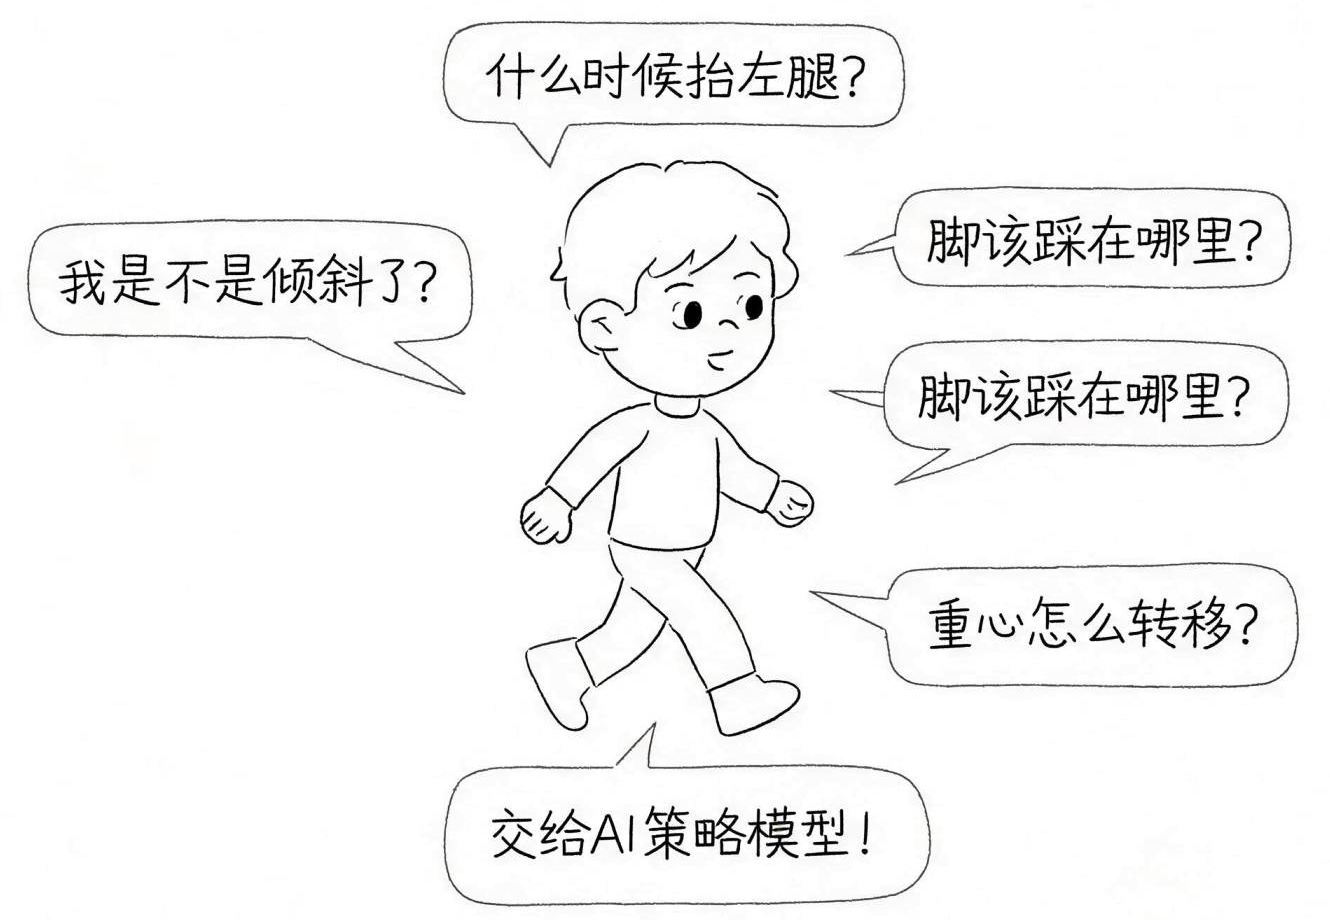

*原课件第 2 页：身体是否倾斜、何时抬腿、脚落在哪里、重心怎样转移，交给 AI 策略模型协调。*

一个看似简单的迈步动作，包含多个相互关联的问题：

- **身体状态：**我是不是倾斜了？需要根据当前姿态判断身体处于什么状态。
- **动作时机：**什么时候抬左腿？动作需要考虑当前支撑和运动过程。
- **落脚位置：**脚该踩在哪里？抬腿和落脚需要与身体运动配合。
- **重心转移：**重心怎么转移？迈步过程中不能只关心一条腿的角度。

课件把这些问题集中到一句话：“交给 AI 策略模型！”重点是让策略结合状态生成相互配合的动作，减少由人逐个关节决定输入的负担。

这里的“大脑”是类比。它强调策略负责根据状态作出动作决策，图中没有给出步态规划公式、落脚点计算方法或具体网络输入，不能仅凭这张图认定网络会分别输出上述每个问题的文字答案。


## 3. 用游戏角色理解状态、动作和反馈

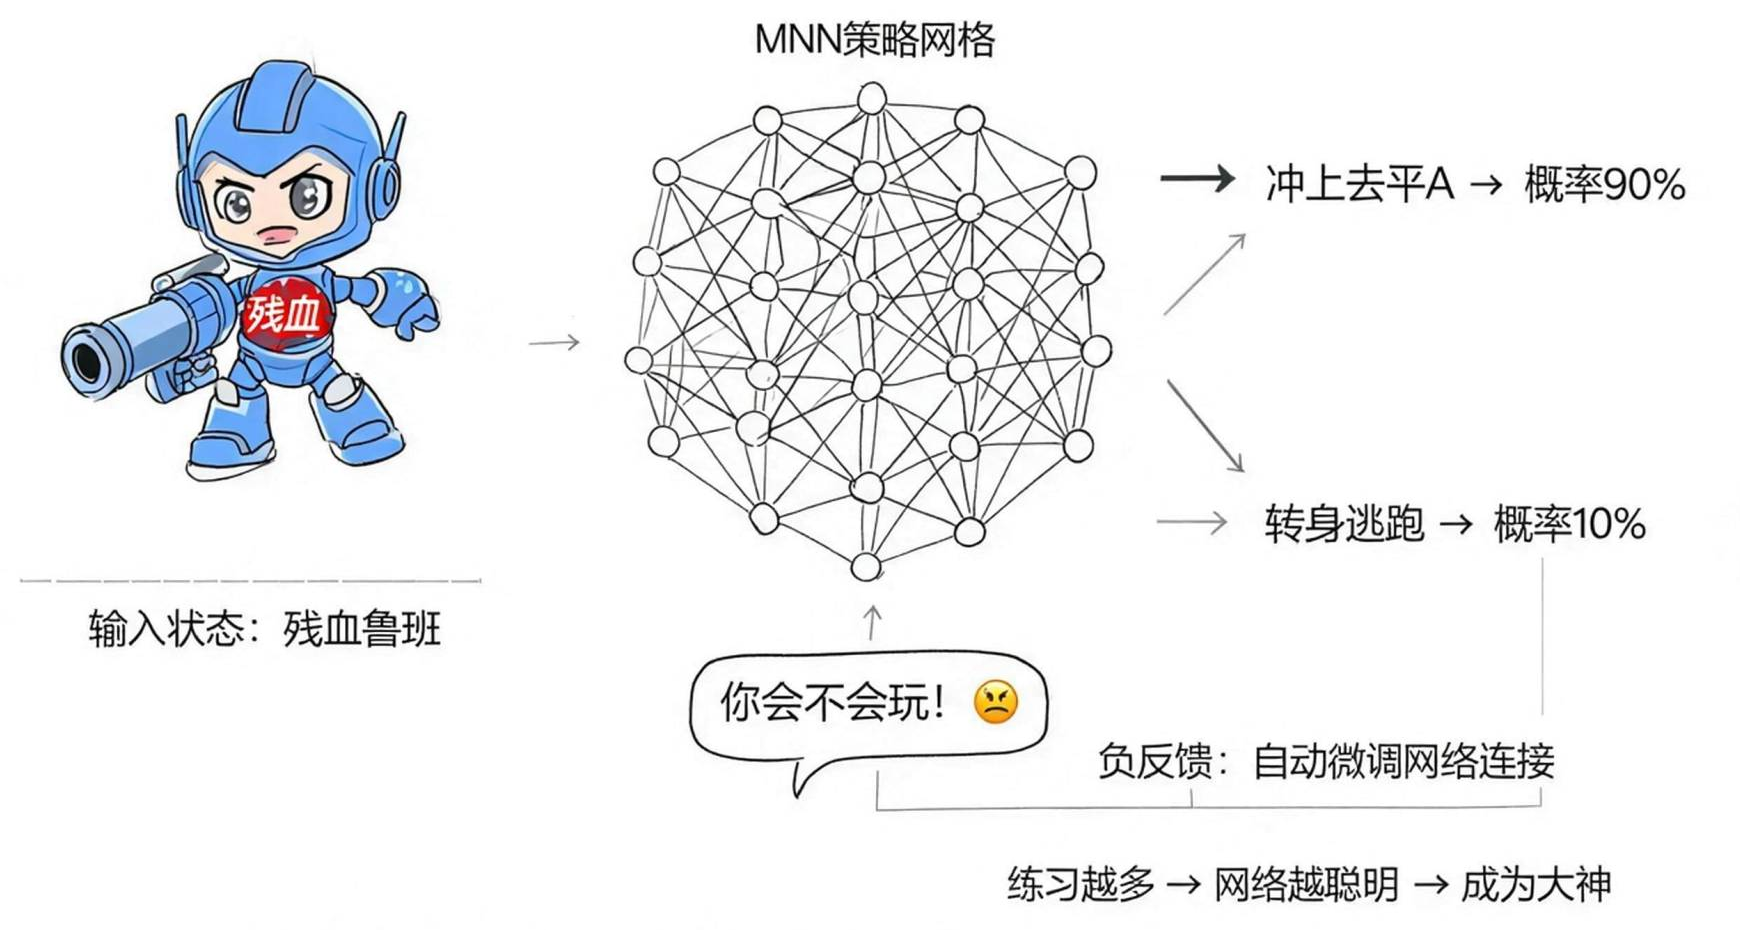

*原课件第 3 页：输入“残血鲁班”，策略给出“冲上去平 A，概率 90%”与“转身逃跑，概率 10%”，再用反馈说明训练。*

### 3.1 输入状态，输出动作选择

课件先给出一个容易理解的状态：游戏角色“残血”。状态进入策略网络后，网络为两种动作给出不同倾向：

| 示例动作 | 图中的概率 |
|---|---|
| 冲上去平 A，即普通攻击 | 90% |
| 转身逃跑 | 10% |

这就是策略的基本作用：**根据状态决定怎样行动**。同一套动作选择机制，可以从游戏中的“攻击还是逃跑”，迁移到理解机器人“根据身体状态生成怎样的关节运动指令”。

图中的两个概率是教学示意，不能当成 T800 策略的实际输出或控制成功率。图中也没有规定，执行时一定选择最高概率动作，还是按概率采样。

### 3.2 用反馈改进策略

图中用“你会不会玩！”表示对动作表现的不满意，并标注“负反馈：自动微调网络连接”，最后以“练习越多 → 网络越聪明 → 成为大神”说明训练过程。

它想表达的是：策略最初不一定选得好，需要通过反复尝试和反馈改进，使之后的决策更合适。联系机器人，学到的策略也需要对动作效果进行评价，逐步形成关节间的协调。

**工程补充：**“微调网络连接”通常指训练时更新网络权重等参数，不是改接机器人的线路，也不一定改变网络拓扑。图中的一句责备只是反馈类比；真实训练需要可供算法使用的评价信号和更新规则，课件没有给出具体奖励函数或优化算法。“练习越多”也不保证表现必然提升，仍取决于训练方法与数据。


## 4. 工程补充：策略怎样接到前面的控制循环

### 4.1 区分训练与推理

**训练**利用数据和反馈更新网络参数；**推理**则使用已有参数，根据当前输入计算动作。把训练好的策略接到仿真主循环时，通常先做推理，并不会因为每次调用网络就自动继续训练。

MNN 是支持模型推理与训练的轻量深度学习框架，策略网络是通过它运行的具体模型。课件中的“MNN 策略网络”可以理解为用 MNN 执行策略计算；框架本身没有自动包含“让 T800 学会走路”的能力，仍需匹配的模型、输入处理和输出解释。

用简单符号表示，一次确定性策略推理可写为：

$$
\mathbf a_t = \pi_\theta(\mathbf o_t)
$$

其中 $\mathbf o_t$ 是时刻 $t$ 输入网络的观测，$\theta$ 是网络参数，$\mathbf a_t$ 是输出动作。观测是按模型要求整理的状态信息，不必等于 MuJoCo 中某一个原始数组。游戏图中的概率形式则可记为 $\pi_\theta(a\mid\mathbf o_t)$，表示给定观测时各动作的概率。

### 4.2 从策略动作到执行器输入

接到第 06～09 篇，完整的数据流可以按以下顺序理解：

1. **读状态：**从仿真或传感器读取当前信息，按策略约定整理观测。
2. **算策略：**通过网络推理得到动作输出。
3. **解释动作：**按模型约定的关节顺序、单位和缩放，把输出转换成控制目标或输入。
4. **送入控制：**完成所需的底层控制和限幅，写入对应执行器的 `data.ctrl`。
5. **推进仿真：**调用 `mj_step()`，下一轮再读取新状态并计算动作。

如果策略输出的是关节目标角度，可以接入第 08 篇的 PD 公式，再按第 09 篇限制最终力矩。如果策略输出的是其他量，就按其接口解释。**本课件没有定义实际输出语义，不能直接把网络结果当作 `qpos` 或 N·m 力矩。**

还需核对输出与执行器的映射。即使上一节模型有 25 个 motor，也不能仅凭这个数量推定策略一定输出 25 个数；策略可能控制其中一部分关节，具体以模型和配置为准。

本节没有足够信息编写课程实际的 MNN 推理脚本，因此不填写猜测的模型路径、张量名称、维度、归一化系数或 PD 参数。它当前解决的是“为什么需要策略，以及策略在控制链路中负责什么”。


## 5. 本课检查与补充参考

完成本节，应能从走路示例说明多关节协调需求，用游戏图解释“状态 → 策略 → 动作”，并区分训练时的参数更新与运行时的策略推理。还应知道策略输出需要按接口转换后进入执行器控制，不能省略单位、顺序和限幅的核对。

本篇已完整核对课件教学页并保留原图。补充说明参考 MNN 官方项目介绍；没有加载课程策略模型、执行策略推理或验证 T800 的行走效果。

- [MNN 官方项目：框架介绍与文档入口](https://github.com/alibaba/MNN#intro)。
- [MNN 官方文档](https://mnn-docs.readthedocs.io/en/latest/)。
